In [1]:
# -----------------------------------------------
# -----------------------------------------------
# LIBRERIE

# Base
import math
import os
from math import sqrt

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)

# Pattern Mining
from fim import (
    fpgrowth,
    apriori,
)

# Xmeans

from pyclustering.cluster import xmeans



In [2]:
# CARICAMENTO DATAFRAME

# Base e Cleaned
df = pd.read_csv("DM1_game_dataset.csv")
df_cleaned = pd.read_csv("df_cleaned.csv")

# Train & Test
train_set = pd.read_csv("train_set.csv")
test_set = pd.read_csv("test_set.csv")

# Imputed
train_imputed = pd.read_csv("train_imputed.csv")
test_imputed = pd.read_csv("test_imputed.csv")

# Transformed
train_transformed = pd.read_csv("train_transformed.csv")
test_transformed = pd.read_csv("test_transformed.csv")

In [3]:
# Identificazione Colonne

# Qualitative
colonne_quali = df_cleaned.select_dtypes(include=["object"]).columns
colonne_quali = colonne_quali + ["BGGId"]

# Ranking
colonne_rank = [
    "Rank:strategygames", "Rank:abstracts", "Rank:familygames",
    "Rank:thematic", "Rank:cgs", "Rank:wargames",
    "Rank:partygames", "Rank:childrensgames"
]
# Categorie
colonne_cat = ["Cat:Thematic", "Cat:Strategy", "Cat:War", "Cat:Family",
               "Cat:CGS", "Cat:Abstract", "Cat:Party", "Cat:Childrens"]

# Binarie
colonne_binarie = ["Kickstarted", "IsReimplementation", "RatingBinaria"]

# Quantitative
colonne_quanti = df_cleaned.select_dtypes(
    include=["int64", "float64"]).columns

# Numeriche
colonne_numeriche = (
    colonne_quanti.tolist()
)
colonne_numeriche = list(dict.fromkeys(colonne_numeriche))

In [4]:
# Misc

# Stile Grafici
sns.set(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 4)

# Scalers
standard_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

# Numerosità
n_train = len(train_set["Rating"])
n_test = len(test_set["Rating"])

In [5]:
# -----------------------------------------------
# -----------------------------------------------
# PATTERN MINING

In [6]:
# Dataset Creation

# RATING -> CAT, MediaPlaytime, ComAgeRec, GameWeight

# Discretizzazione
# in questo modo perchè df_cleaned ha ancora valori da imputare
df_pattern_prov = pd.concat([train_imputed, test_imputed],
                            axis=0, ignore_index=True)

df_pattern = df_pattern_prov.join(df[colonne_cat])
df_pattern = df_pattern[(df_pattern[colonne_cat] != 0).any(axis=1)]

# Category
df_pattern["Category"] = "0"


def estraicategorie(riga):
    # Prendiamo il nome della colonna (senza il prefisso 'Cat:') se il valore è > 0
    attive = [col.replace("Cat:", "") for col in colonne_cat if riga[col] != 0]
    # Uniamo i nomi con un underscore
    return "/".join(attive)


df_pattern["Category"] = df_pattern.apply(estraicategorie, axis=1)


# Weight
df_pattern["Weight_Bin"] = df_pattern["GameWeight"].round()


# Playtime
condizione1 = [
    (df_pattern['MediaPlaytime'] <= 30),
    (df_pattern['MediaPlaytime'] > 30) & (
        df_pattern['MediaPlaytime'] <= 60),
    (df_pattern['MediaPlaytime'] > 60) & (
        df_pattern['MediaPlaytime'] <= 120),
    (df_pattern['MediaPlaytime'] > 120)
]
tempo = [
    '0-30',
    '30-60',
    '60-120',
    '120+']
df_pattern['Playtime_Bin'] = np.select(condizione1, tempo, default=None)


# Recommended Age
condizione2 = [
    (df_pattern['ComAgeRec'] <= 6),
    (df_pattern['ComAgeRec'] > 6) & (
        df_pattern['ComAgeRec'] <= 14),
    (df_pattern['ComAgeRec'] > 14) & (
        df_pattern['ComAgeRec'] < 18),
    (df_pattern['ComAgeRec'] >= 18)
]
eta_rac = [
    '0-6',
    '7-13',
    '14-17',
    "18+"
]
df_pattern['RecommendedAge_Bin'] = np.select(
    condizione2, eta_rac, default=None)


df_pattern["Category"] = df_pattern["Category"].astype(str) + "_CAT"
df_pattern["Weight_Bin"] = df_pattern["Weight_Bin"].astype(str) + "_Weight"
df_pattern["RecommendedAge_Bin"] = df_pattern["RecommendedAge_Bin"].astype(
    str) + "_Age"
df_pattern["Playtime_Bin"] = df_pattern["Playtime_Bin"].astype(
    str) + "_Playtime"
df_pattern["Rating"] = df_pattern["Rating"] + "_Rating"


df_pattern = df_pattern.select_dtypes(include=["object"])
df_pattern = df_pattern.drop(["Family", "Period"], axis=1)

pm = df_pattern.values.tolist()

In [7]:
# -----------------------------------------------
# -----------------------------------------------
# APRIORI

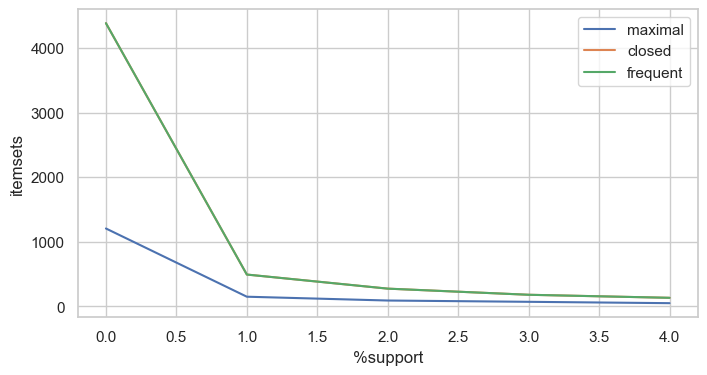

In [8]:
# Support Plot

len_max_it = []
len_cl_it = []
len_fr_it = []
max_supp = 5
zmin_plot = 2
for i in range(0, max_supp):
    max_itemsets = apriori(pm, target="m", supp=i, zmin=zmin_plot)
    cl_itemsets = apriori(pm, target="c", supp=i, zmin=zmin_plot)
    fr_itemsets = apriori(pm, target="s", supp=i, zmin=zmin_plot)
    len_max_it.append(len(max_itemsets))
    len_cl_it.append(len(cl_itemsets))
    len_fr_it.append(len(cl_itemsets))


plt.plot(np.arange(0, max_supp), len_max_it, label="maximal")
plt.plot(np.arange(0, max_supp), len_cl_it, label="closed")
plt.plot(np.arange(0, max_supp), len_fr_it, label="frequent")
plt.legend()
plt.xlabel("%support")
plt.ylabel("itemsets")
plt.show()

# si evince che closed e frequent sono pressochè identici; con 0 di SUPP in teoria sono profondamente diversi (circa 1000 pattern), ma già da 0.1 hanno una differenza di semplici decine,
# ad 1 (prob anche prima) sono identici

In [9]:
# Iperparametri
supp = 2.5
zmin = 2
conf = 64


In [10]:
# Frequent

itemsets = apriori(pm, target="s", supp=supp, zmin=zmin, report="S")
pd.DataFrame(itemsets, columns=["frequent_itemset", "support"])

,frequent_itemset,support
0,"(Strategy/Family_CAT, 7-13_Age)",2.823777
1,"(Party_CAT, 7-13_Age)",3.187518
2,"(4.0_Weight, 120+_Playtime)",3.149229
3,"(4.0_Weight, High_Rating)",3.809706
4,"(4.0_Weight, 7-13_Age)",3.168374
...,...,...
210,"(Medium_Rating, 7-13_Age)",36.048626
211,"(2.0_Weight, 0-30_Playtime)",17.411697
212,"(2.0_Weight, 0-30_Playtime, 7-13_Age)",15.794008
213,"(2.0_Weight, 7-13_Age)",39.820044


In [11]:
# Closed

itemsets = apriori(pm, target="c", supp=supp, zmin=zmin, report="S")
pd.DataFrame(itemsets, columns=["closed_itemset", "support"])

,closed_itemset,support
0,"(Strategy/Family_CAT, 7-13_Age)",2.823777
1,"(Party_CAT, 7-13_Age)",3.187518
2,"(4.0_Weight, 120+_Playtime)",3.149229
3,"(4.0_Weight, High_Rating)",3.809706
4,"(4.0_Weight, 7-13_Age)",3.168374
...,...,...
210,"(Medium_Rating, 7-13_Age)",36.048626
211,"(2.0_Weight, 0-30_Playtime)",17.411697
212,"(2.0_Weight, 0-30_Playtime, 7-13_Age)",15.794008
213,"(2.0_Weight, 7-13_Age)",39.820044


In [12]:
# Maximal

itemsets = apriori(pm, target="m", supp=supp, zmin=zmin, report="S")
pd.DataFrame(itemsets, columns=["maximal_itemset", "support"])

,maximal_itemset,support
0,"(Strategy/Family_CAT, 7-13_Age)",2.823777
1,"(Party_CAT, 7-13_Age)",3.187518
2,"(4.0_Weight, 120+_Playtime)",3.149229
3,"(4.0_Weight, High_Rating)",3.809706
4,"(4.0_Weight, 7-13_Age)",3.168374
...,...,...
74,"(War_CAT, Low_Rating, 0-30_Playtime, 7-13_Age)",3.608691
75,"(War_CAT, Medium_Rating, 2.0_Weight, 0-30_Play...",2.670623
76,"(1.0_Weight, Low_Rating, 0-30_Playtime, 7-13_Age)",7.073801
77,"(1.0_Weight, Medium_Rating, 0-30_Playtime, 7-1...",6.480329


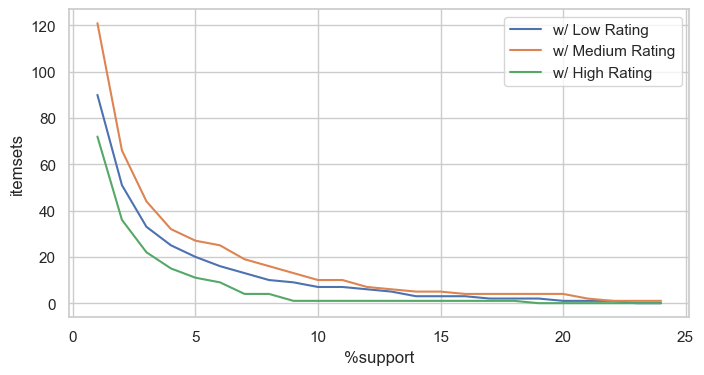

In [13]:
# Support vs Rating

filter_1 = []
filter_2 = []
filter_3 = []
max_supp = 25
for i in range(1, max_supp):
    max_itemsets = apriori(pm, target="s", supp=i, zmin=zmin)
    filter_1.append(
        len([item for item in max_itemsets if "Low_Rating" in item[0]]))
    filter_2.append(
        len([item for item in max_itemsets if "Medium_Rating" in item[0]]))
    filter_3.append(
        len([item for item in max_itemsets if "High_Rating" in item[0]]))

plt.plot(np.arange(1, max_supp), filter_1, label="w/ Low Rating")
plt.plot(np.arange(1, max_supp), filter_2, label="w/ Medium Rating")
plt.plot(np.arange(1, max_supp), filter_3, label="w/ High Rating")
plt.legend()
plt.xticks()
plt.xlabel("%support")
plt.ylabel("itemsets")
plt.show()

In [14]:
# Rules
rules = apriori(pm, target="r", supp=supp, zmin=zmin, conf=conf, report="aScl")
rules_df = pd.DataFrame(
    rules,
    columns=[
        "consequent",
        "antecedent",
        "abs_support",
        "%_support",
        "confidence",
        "lift",
    ],
)
rules_df.sort_values(by="lift", axis=0, ascending=False)

,consequent,antecedent,abs_support,%_support,confidence,lift
4,High_Rating,"(4.0_Weight,)",398,3.809706,0.704425,3.012331
3,High_Rating,"(4.0_Weight, 7-13_Age)",233,2.230305,0.703927,3.010205
25,1.0_Weight,"(0-6_Age, Low_Rating, 0-30_Playtime)",615,5.886857,0.912463,3.008996
2,High_Rating,"(4.0_Weight, 120+_Playtime)",230,2.201589,0.699088,2.989510
26,1.0_Weight,"(0-6_Age, Low_Rating)",678,6.489901,0.885117,2.918820
...,...,...,...,...,...,...
118,7-13_Age,"(War_CAT, 1.0_Weight, Medium_Rating)",246,2.354743,0.689076,0.889396
137,7-13_Age,"(1.0_Weight, Medium_Rating)",830,7.944865,0.685384,0.884631
116,7-13_Age,"(War_CAT, 1.0_Weight, Medium_Rating, 0-30_Play...",207,1.981430,0.665595,0.859089
134,7-13_Age,"(1.0_Weight, Medium_Rating, 0-30_Playtime)",677,6.480329,0.657920,0.849184


In [15]:
# Classification
rules_df[rules_df["consequent"] == "High_Rating"]

,consequent,antecedent,abs_support,%_support,confidence,lift
2,High_Rating,"(4.0_Weight, 120+_Playtime)",230,2.201589,0.699088,2.989510
3,High_Rating,"(4.0_Weight, 7-13_Age)",233,2.230305,0.703927,3.010205
4,High_Rating,"(4.0_Weight,)",398,3.809706,0.704425,3.012331


In [16]:
len_r = []

min_sup = 2
max_sup = 10.0
step_sup = 0.2
support_range = np.arange(min_sup, max_sup, step_sup)

min_conf = 0
max_conf = 60
step_conf = 1
conf_range = np.arange(min_conf, max_conf, step_conf)

for i in support_range:  # support
    len_r_wrt_i = []
    for j in conf_range:  # confidence
        rules = apriori(pm, target="r", supp=i,
                        zmin=zmin, conf=j, report="aScl")
        # study your characteristics/properties here
        len_r_wrt_i.append(len(rules))

    len_r.append(len_r_wrt_i)
len_r = np.array(len_r)


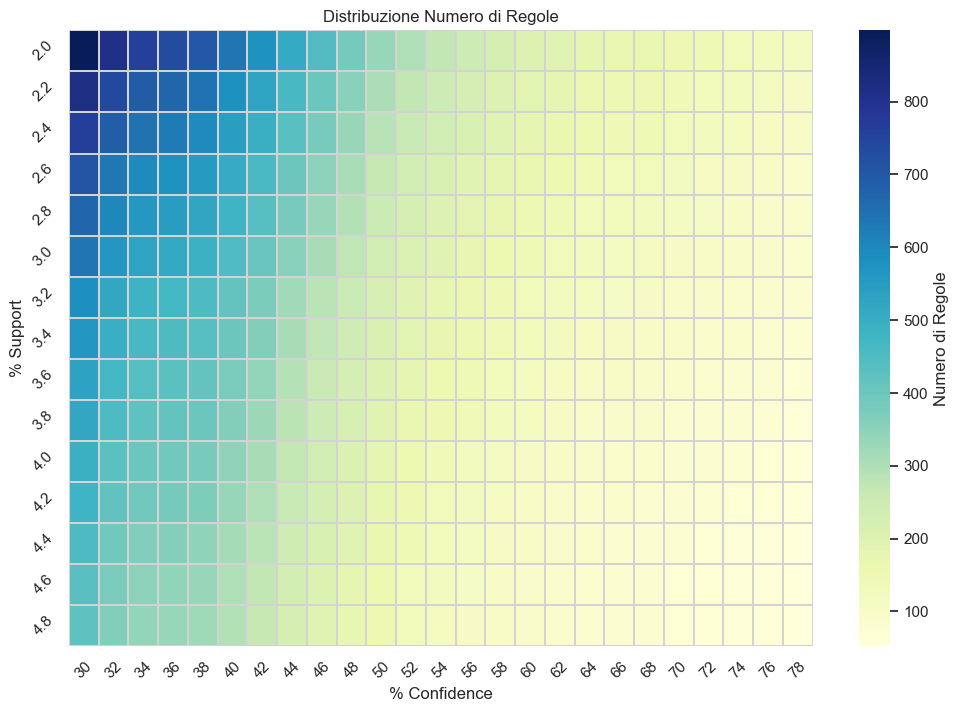

In [17]:

# --- 1. Definizione Range Ottimizzati (Zoom sulla zona utile) ---
min_sup, max_sup, step_sup = 2.0, 5.0, 0.2  # Abbassato il max_sup per vedere meglio
support_range = np.round(np.arange(min_sup, max_sup, step_sup), 2)

min_conf, max_conf, step_conf = 30, 80, 2    # Partiamo da 5% per evitare il rumore iniziale
conf_range = np.arange(min_conf, max_conf, step_conf)

# --- 2. Logica di calcolo (Assicurati che len_r sia popolata con i nuovi range) ---
len_r = []
for i in support_range:
    len_r_wrt_i = []
    for j in conf_range:
        rules = apriori(pm, target="r", supp=i, zmin=zmin, conf=j, report="aScl")
        len_r_wrt_i.append(len(rules))
    len_r.append(len_r_wrt_i)
len_r = np.array(len_r)



plt.figure(figsize=(12, 8))

sns.heatmap(len_r, 
            cmap="YlGnBu",      
            xticklabels=conf_range, 
            yticklabels=support_range,
            linewidths=0.1, 
            linecolor='lightgray',
            cbar_kws={'label': 'Numero di Regole'})

plt.xlabel("% Confidence")
plt.ylabel("% Support")
plt.title("Distribuzione Numero di Regole")
plt.xticks(rotation=45)
plt.yticks(rotation=45)
plt.show()

In [18]:
# -----------------------------------------------
# -----------------------------------------------
# EFFEPI-GROWTH

In [19]:
#frequent
itemsets = fpgrowth(pm, target="s", supp=supp, zmin=zmin, report="S")
pd.DataFrame(itemsets, columns=["frequent_itemset", "support"])

,frequent_itemset,support
0,"(0-30_Playtime, 7-13_Age)",31.970901
1,"(2.0_Weight, 7-13_Age)",39.820044
2,"(2.0_Weight, 0-30_Playtime, 7-13_Age)",15.794008
3,"(2.0_Weight, 0-30_Playtime)",17.411697
4,"(Medium_Rating, 7-13_Age)",36.048626
...,...,...
210,"(4.0_Weight, 7-13_Age)",3.168374
211,"(4.0_Weight, High_Rating)",3.809706
212,"(4.0_Weight, 120+_Playtime)",3.149229
213,"(Party_CAT, 7-13_Age)",3.187518


In [20]:
#closed
itemsets = fpgrowth(pm, target="c", supp=supp, zmin=zmin, report="S")
pd.DataFrame(itemsets, columns=["closed_itemset", "support"])

,closed_itemset,support
0,"(Strategy/Family_CAT, 7-13_Age)",2.823777
1,"(Party_CAT, 7-13_Age)",3.187518
2,"(4.0_Weight, 120+_Playtime)",3.149229
3,"(4.0_Weight, High_Rating)",3.809706
4,"(4.0_Weight, 7-13_Age)",3.168374
...,...,...
210,"(Medium_Rating, 7-13_Age)",36.048626
211,"(2.0_Weight, 0-30_Playtime, 7-13_Age)",15.794008
212,"(2.0_Weight, 0-30_Playtime)",17.411697
213,"(2.0_Weight, 7-13_Age)",39.820044


In [21]:
rules = fpgrowth(pm, target="r", supp=supp, zmin=zmin, conf=conf, report="aScl")
pd.DataFrame(
    rules,
    columns=[
        "consequent",
        "antecedent",
        "abs_support",
        "%_support",
        "confidence",
        "lift",
    ],
)

,consequent,antecedent,abs_support,%_support,confidence,lift
0,7-13_Age,"(0-30_Playtime,)",3340,31.970901,0.722318,0.932303
1,7-13_Age,"(2.0_Weight,)",4160,39.820044,0.905135,1.168266
2,7-13_Age,"(2.0_Weight, 0-30_Playtime)",1650,15.794008,0.907092,1.170792
3,7-13_Age,"(Medium_Rating,)",3766,36.048626,0.819587,1.057848
4,7-13_Age,"(Medium_Rating, 0-30_Playtime)",1662,15.908873,0.787305,1.016181
...,...,...,...,...,...,...
145,High_Rating,"(4.0_Weight, 7-13_Age)",233,2.230305,0.703927,3.010205
146,High_Rating,"(4.0_Weight,)",398,3.809706,0.704425,3.012331
147,High_Rating,"(4.0_Weight, 120+_Playtime)",230,2.201589,0.699088,2.989510
148,7-13_Age,"(Party_CAT,)",333,3.187518,0.794749,1.025790
